<img src="https://github.com/juanatga/DSB-Unit-03/blob/main/labs/02%20-%20Classification-LeftHanded/assets/ga-logo.png?raw=1" style="float: left; margin: 20px; height: 55px">

# Lab: Classification: Predicting Left-Handedness from Psychological Factors

---

One way to define the data science process is as follows:

1. Define the problem.
2. Obtain the data.
3. Explore the data.
4. Model the data.
5. Evaluate the model.
6. Answer the problem.

We'll walk through a full data science problem in this lab.

---
## Step 1: Define The Problem.

You're currently a data scientist working at a university. A professor of psychology is attempting to study the relationship between personalities and left-handedness. They have tasked you with gathering evidence so that they may publish.

As a data scientist, you know that any real data science problem must be **specific** and **conclusively answerable**. For example:
- Bad data science problem: "What is the link between obesity and blood pressure?"
    - This is vague and is not conclusively answerable. That is, two people might look at the conclusion and one may say "Sure, the problem has been answered!" and the other may say "The problem has not yet been answered."
- Good data science problem: "Does an association exist between obesity and blood pressure?"
    - This is more specific and is conclusively answerable. The problem specifically is asking for a "Yes" or "No" answer. Based on that, two independent people should both be able to say either "Yes, the problem has been answered" or "No, the problem has not yet been answered."
- Excellent data science problem: "As obesity increases, how does blood pressure change?"
    - This is very specific and is conclusively answerable. The problem specifically seeks to understand the effect of one variable on the other.

### In the context of the left-handedness and personality example, what are three specific and conclusively answerable problems that you could answer using data science?

> You might find it helpful to check out the codebook in the repo for some inspiration.

**Answer:** three specific, conclusively answerable problems:

1. **Is there an association between any single survey item (Q1–Q44) and writing hand?** For each item, does the mean response of left-handed respondents differ significantly from that of right-handed respondents? The answer is a yes or no for each item.
2. **Can a classifier trained only on the answers to Q1–Q44 predict whether a respondent is left-handed more accurately than always guessing "right-handed" (the baseline accuracy)?** The answer is a yes or no.
3. **As agreement with "I have taken apart machines just to see how they work" (Q35) increases by one point on the 5-point scale, how do the odds of being left-handed change?** This asks for the direction and size of an effect, which a logistic-regression coefficient can answer.

---
## Step 2: Obtain the data.

### Read in the file titled "data.csv":
> Hint: Despite being saved as a .csv file, you won't be able to simply `pd.read_csv()` this data!

In [ ]:
# library imports
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score, recall_score, precision_score

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.8.0


In [5]:
# The file is tab-separated despite the .csv extension
# DATA_PATH = "./data.csv"
DATA_PATH = "https://raw.githubusercontent.com/CharleyHananiaGA/DSB-Unit-03/refs/heads/main/labs/02%20-%20Classification-LeftHanded/data/data.csv"

df = pd.read_csv(DATA_PATH, sep="\t")
print(df.shape)
df.head()

(4184, 56)


,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,Q11,Q12,Q13,Q14,Q15,Q16,Q17,Q18,Q19,Q20,Q21,Q22,Q23,Q24,Q25,Q26,Q27,Q28,Q29,Q30,Q31,Q32,Q33,Q34,Q35,Q36,Q37,Q38,Q39,Q40,Q41,Q42,Q43,Q44,introelapse,testelapse,country,fromgoogle,engnat,age,education,gender,orientation,race,religion,hand
0,4,1,5,1,5,1,5,1,4,1,1,1,5,5,5,1,5,1,5,1,5,1,1,1,5,5,5,1,5,1,1,1,1,5,5,1,1,1,5,5,5,1,5,1,91,232,US,2,1,22,3,1,1,3,2,3
1,1,5,1,4,2,5,5,4,1,5,2,5,3,4,1,4,1,1,1,5,2,4,4,4,1,2,1,2,1,3,1,5,2,4,4,4,4,4,1,3,1,4,4,5,17,247,CA,2,1,14,1,2,2,6,1,1
2,1,2,1,1,5,4,3,2,1,4,4,5,4,3,4,1,2,3,1,3,3,3,4,5,3,2,2,2,1,4,3,3,4,4,2,2,4,2,1,4,2,2,2,2,11,6774,NL,2,2,30,4,1,1,1,1,2
3,1,4,1,5,1,4,5,4,3,5,1,3,2,3,1,5,2,2,5,5,2,3,2,2,1,4,1,1,1,3,4,1,3,5,5,1,3,4,1,2,1,1,1,3,14,1072,US,2,1,18,2,2,5,3,2,2
4,5,1,5,1,5,1,5,1,3,1,1,1,5,5,5,1,5,1,5,2,5,1,5,1,5,5,5,1,5,1,5,1,5,5,5,1,1,1,5,5,5,1,5,1,10,226,US,2,1,22,3,1,1,3,2,3


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4184 entries, 0 to 4183
Data columns (total 56 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Q1           4184 non-null   int64 
 1   Q2           4184 non-null   int64 
 2   Q3           4184 non-null   int64 
 3   Q4           4184 non-null   int64 
 4   Q5           4184 non-null   int64 
 5   Q6           4184 non-null   int64 
 6   Q7           4184 non-null   int64 
 7   Q8           4184 non-null   int64 
 8   Q9           4184 non-null   int64 
 9   Q10          4184 non-null   int64 
 10  Q11          4184 non-null   int64 
 11  Q12          4184 non-null   int64 
 12  Q13          4184 non-null   int64 
 13  Q14          4184 non-null   int64 
 14  Q15          4184 non-null   int64 
 15  Q16          4184 non-null   int64 
 16  Q17          4184 non-null   int64 
 17  Q18          4184 non-null   int64 
 18  Q19          4184 non-null   int64 
 19  Q20          4184 non-null 

---

## Step 3: Explore the data.

### Conduct background research:

Domain knowledge is irreplaceable. Figuring out what information is relevant to a problem, or what data would be useful to gather, is a major part of any end-to-end data science project! For this lab, you'll be using a dataset that someone else has put together, rather than collecting the data yourself.

Do some background research about personality and handedness. What features, if any, are likely to help you make good predictions? How well do you think you'll be able to model this? Write a few bullet points summarizing what you believe, and remember to cite external sources.

You don't have to be exhaustive here. Do enough research to form an opinion, and then move on.

> You'll be using the answers to Q1-Q44 for modeling; you can disregard other features, e.g. country, age, internet browser.

**Background research: what I expect going in**

- **Left-handers are a small minority, so the classes will be imbalanced.** A meta-analysis of over 2 million people by Papadatou-Pastou et al. (2020) puts the best estimate of left-handedness at about 10.6%. Depending on how it is measured, the figure ranges from 9.3% to 18.1%. Mixed-handedness (around 9%) is almost as common as left-handedness. A model that always guesses "right-handed" will therefore already be about 89–90% accurate, which is a hard baseline to beat.
- **Evidence for personality differences is weak and inconsistent.** Some studies report small effects. In a lab study of 432 undergraduates, Sartarelli (2016) found left-handers scored somewhat higher on agreeableness on the Big Five, but did not differ in cognitive ability or earnings. Others find little or nothing: an analysis of a large Open Psychometrics Big Five dataset (2023 preprint) found no significant handedness differences in three of the five traits. Older work linking left-handedness to anxiety or behavioural inhibition has had mixed replication results (Beaton et al., 2015).
- **This survey doesn't measure personality directly.** The Open Sex Role Inventory items capture *gender-typed interests and behaviours* (guns, dancing, baking, video games). The best-established demographic correlate of handedness is sex: males have about 1.23 times the odds of being left-handed compared with females (Papadatou-Pastou et al., 2008). Any signal in Q1–Q44 is likely to be a weak, indirect echo of gender.
- **Expectation:** the features will be only weakly related to handedness. I expect the models to perform at or barely above the baseline accuracy rate, with ROC AUC close to 0.5 (chance).

**Sources**

- Papadatou-Pastou, M., Ntolka, E., Schmitz, J., et al. (2020). Human handedness: A meta-analysis. *Psychological Bulletin*. doi:10.1037/bul0000229. https://research-repository.st-andrews.ac.uk/handle/10023/19889
- Papadatou-Pastou, M., Martin, M., Munafò, M. R., & Jones, G. V. (2008). Sex differences in left-handedness: A meta-analysis of 144 studies. *Psychological Bulletin, 134*(5), 677–699. doi:10.1037/a0012814. https://wrap.warwick.ac.uk/29434/
- Sartarelli, M. (2016). Handedness, earnings, ability and personality: Evidence from the lab. *PLoS ONE*. https://www.ncbi.nlm.nih.gov/pmc/articles/PMC5082911/
- Beaton, A. A., et al. (2015). Handedness and Behavioural Inhibition System/Behavioural Activation System scores: A replication. https://openaccess.city.ac.uk/id/eprint/15885/
- Handedness and Big Five personality traits in the Open Psychometrics IPIP dataset (2023 preprint). https://www.preprints.org/manuscript/202312.2139

### Conduct exploratory data analysis on this dataset:

If you haven't already, be sure to check out the codebook in the repo, as that will help in your EDA process.

You might use this section to perform data cleaning if you find it to be necessary.

In [7]:
df.columns

Index(['Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10', 'Q11',
       'Q12', 'Q13', 'Q14', 'Q15', 'Q16', 'Q17', 'Q18', 'Q19', 'Q20', 'Q21',
       'Q22', 'Q23', 'Q24', 'Q25', 'Q26', 'Q27', 'Q28', 'Q29', 'Q30', 'Q31',
       'Q32', 'Q33', 'Q34', 'Q35', 'Q36', 'Q37', 'Q38', 'Q39', 'Q40', 'Q41',
       'Q42', 'Q43', 'Q44', 'introelapse', 'testelapse', 'country',
       'fromgoogle', 'engnat', 'age', 'education', 'gender', 'orientation',
       'race', 'religion', 'hand'],
      dtype='object')

In [8]:
q_cols = [f"Q{i}" for i in range(1, 45)]

print("Missing values (NaN):", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# Herr I am checking my target column: hand
print("\nhand (1=Right, 2=Left, 3=Both, 0=not answered):")
print(df["hand"].value_counts().sort_index())

Missing values (NaN): 0
Duplicate rows: 0

hand (1=Right, 2=Left, 3=Both, 0=not answered):
hand
0      11
1    3542
2     452
3     179
Name: count, dtype: int64


In [ ]:
# Valid answers are 1-5; check what actually appears in the Q columns
print(df[q_cols].stack().value_counts().sort_index())
print("\nRespondents with at least one 0 answer:", (df[q_cols] == 0).any(axis=1).sum())

0      697
1    48607
2    25608
3    29664
4    36661
5    42859
Name: count, dtype: int64

Respondents with at least one 0 answer: 381


**Data cleaning decisions**

- **`hand = 0` (11 rows):** the respondent didn't answer the question, so we can't know their handedness. These rows are dropped.
- **`hand = 3`, "Both" (179 rows):** the question is about left-handedness, and ambidextrous writers belong to neither group cleanly. Labelling them "not left-handed" would mix them into the right-handed class. We drop them, so the target compares **left-handed (1)** against **right-handed (0)**.
- **0 answers in Q1–Q44:** 0 isn't on the 1–5 scale; it means the item was skipped (about 0.4% of all answers). We convert these to `NaN` and impute them later with the median of the **training set only**, so no information leaks from the test set.

In [12]:
# I only want values of hand that are either 1 or 2
df = df[df["hand"].isin([1, 2])].copy()

# The above can also be done with drop rows or with a filter

# New column for the left handed people only
# You can also do this with get dummies
df["left"] = (df["hand"] == 2).astype(int)

# You want to replace the zero values with a Nan, so you can later drop the Nans
df[q_cols] = df[q_cols].replace(0, np.nan)

print(df.shape)
print(df["left"].value_counts())

(3994, 57)
left
0    3542
1     452
Name: count, dtype: int64


<Axes: >

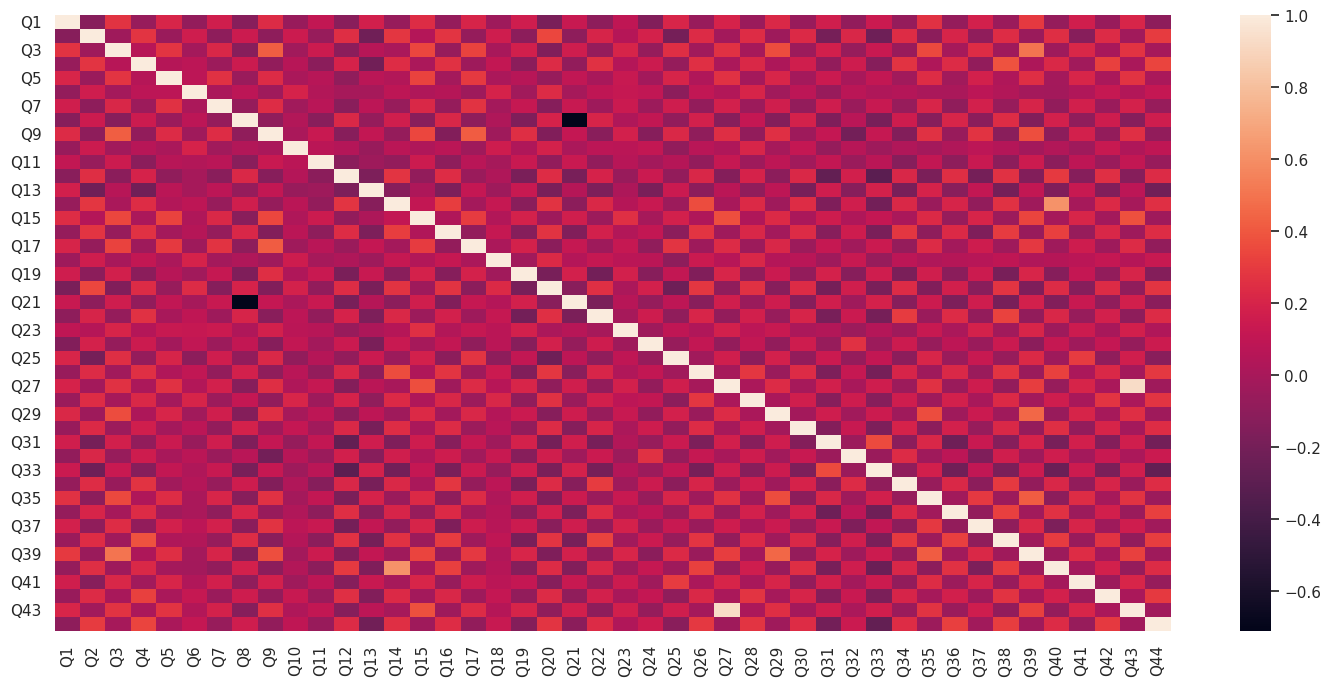

In [25]:
corr_mtx = df[q_cols].corr()

plt.figure(figsize=(18, 8))
sns.heatmap(corr_mtx)

In [ ]:
# Q27 and Q43 have identical wording in the codebook
print("Correlation Q27 vs Q43:", round(df["Q27"].corr(df["Q43"]), 3))
print("Identical answers:", round((df["Q27"] == df["Q43"]).mean(), 3))

Correlation Q27 vs Q43: 0.928
Identical answers: 0.81


Q27 and Q43 are the **same question asked twice** ("I think a natural disaster would be kind of exciting"). Their answers correlate at about 0.93. The lab says to use all Q columns, so we keep both, but this redundancy should be kept in mind when interpreting coefficients.

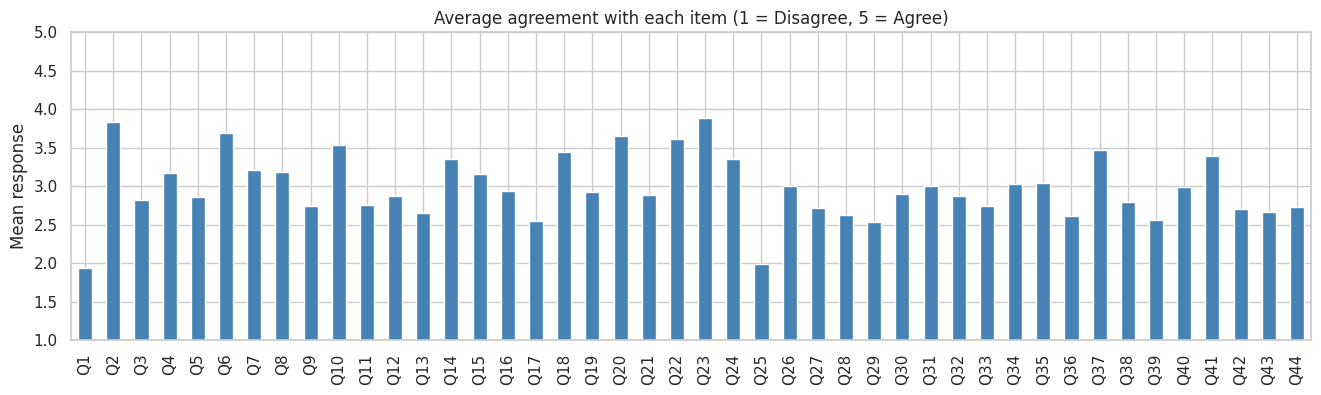

In [23]:
fig, ax = plt.subplots(figsize=(16, 4))
df[q_cols].mean().plot(kind="bar", ax=ax, color="steelblue")
ax.set(title="Average agreement with each item (1 = Disagree, 5 = Agree)", ylabel="Mean response", ylim=(1, 5));

Strongest correlations:
Q8    -0.048
Q23   -0.038
Q22   -0.037
Q25    0.018
Q5     0.018
Q26    0.023
dtype: float64


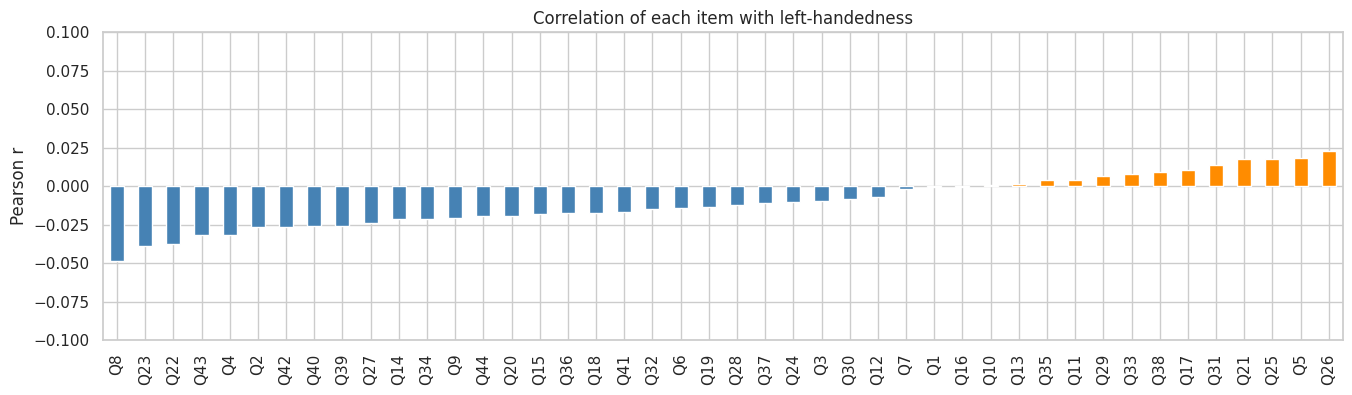

In [24]:
# How strongly is each item related to being left-handed?
corr_with_left = df[q_cols].corrwith(df["left"]).sort_values()

fig, ax = plt.subplots(figsize=(16, 4))
corr_with_left.plot(kind="bar", ax=ax, color=np.where(corr_with_left > 0, "darkorange", "steelblue"))
ax.set(title="Correlation of each item with left-handedness", ylabel="Pearson r", ylim=(-0.1, 0.1))
print("Strongest correlations:")
print(corr_with_left.iloc[[0, 1, 2, -3, -2, -1]].round(3))

In [ ]:
# Not used for modelling, but relevant to the background research
gender_labels = {0: "Not answered", 1: "Male", 2: "Female", 3: "Other"}
(df.assign(gender=df["gender"].map(gender_labels))
   .groupby("gender")["left"].agg(["mean", "count"])
   .rename(columns={"mean": "share left-handed"}).round(3))

,share left-handed,count
gender,,
Female,0.098,2126
Male,0.128,1517
Not answered,0.216,74
Other,0.119,277


**EDA findings**

- **Clean file otherwise:** there are no `NaN` values and no duplicate rows. Missing answers are coded as 0, which we have now converted.
- **Imbalanced target:** about 11.3% of the left/right respondents are left-handed. That is close to the ~10.6% population estimate from the literature.
- **Weak relationships:** no item correlates with left-handedness by more than about ±0.05 in absolute value. The strongest is Q8 ("I know the birthdays of my friends"), at about −0.05, which is negligible. This is an early warning that the Q items carry very little information about handedness.
- **Sex difference:** male respondents are more often left-handed than female respondents, in line with the literature. Sex is not one of the modelling features, though.

### Calculate and interpret the baseline accuracy rate:

In [ ]:
baseline = df["left"].value_counts(normalize=True)
print(baseline.round(4))
print(f"\nBaseline accuracy: {baseline.max():.2%}")

left
0    0.8868
1    0.1132
Name: proportion, dtype: float64

Baseline accuracy: 88.68%


**Baseline accuracy ≈ 88.7%.** If we ignore every feature and always predict the majority class ("right-handed"), we are correct about 88.7% of the time. A model is only adding value if it beats this. With a rare target, accuracy alone can also be misleading: a model that never predicts "left-handed" still scores 88.7%. So we'll also check whether models ever identify any left-handers.

### Short answer questions:

In this lab you'll use K-nearest neighbors and logistic regression to model handedness based off of psychological factors. Answer the following related questions; your answers may be in bullet points.

#### Describe the difference between regression and classification problems:

- **Regression** predicts a **continuous, numeric** target (e.g. house price, temperature). The output can be any value on a range. It is evaluated with metrics such as RMSE, MAE and R².
- **Classification** predicts a **categorical** target, i.e. which class an observation belongs to (e.g. left- vs right-handed, spam vs not spam). Models often output a class probability that is then thresholded. They are evaluated with metrics such as accuracy, precision, recall and ROC AUC.
- This lab is a **binary classification** problem.

#### Considering $k$-nearest neighbors, describe the relationship between $k$ and the bias-variance tradeoff:

- **Small k (e.g. k = 1):** the prediction depends on very few neighbours, so the decision boundary is jagged and follows noise in the training data. This gives **low bias and high variance**, so the model tends to overfit.
- **Large k:** each prediction averages over many neighbours, which smooths the boundary. This gives **higher bias and lower variance**, so the model tends to underfit. In the extreme, k = n always predicts the majority class.
- **Increasing k therefore trades variance for bias.** The best k sits between the extremes.

#### Why do we often standardize predictor variables when using $k$-nearest neighbors?

- k-NN classifies by **distance** (e.g. Euclidean) between observations, so every feature's scale directly affects which neighbours are "nearest".
- A feature measured on a large scale (e.g. income in dollars) would dominate one on a small scale (e.g. number of children), even if the small-scale feature is more informative.
- **Standardising** (mean 0, standard deviation 1) puts features on a comparable scale, so each contributes fairly to the distance.

#### Do you think we should standardize the explanatory variables for this problem? Why or why not?

**Not necessary here.** All of Q1–Q44 are measured on the **same 1–5 agreement scale**, so no feature can dominate the distance calculation just because of its units. The items do have somewhat different spreads, but those differences are real: an item people disagree on more is genuinely more spread out. Standardising would be harmless, but it isn't needed, so we **use the raw 1–5 responses**. (If we added features such as age or `testelapse`, which are on completely different scales, standardising would become essential.)

#### How do we settle on $k$ for a $k$-nearest neighbors model?

- Treat **k as a hyperparameter** and choose it by **validation performance**, not training performance (training accuracy is always best at k = 1).
- In practice, try a range of k values with **cross-validation** on the training set (e.g. `GridSearchCV`), then pick the k with the best average validation score. The test set is reserved for the final evaluation.
- Practical tips: use an **odd k** in binary problems to avoid tied votes. Plot validation accuracy against k to see where performance peaks or levels off. Choose the metric to match the goal; with an imbalanced target, ROC AUC or recall may matter more than accuracy.

#### What is the default type of regularization for logistic regression as implemented in scikit-learn? (You might [check the documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).)

**L2 (Ridge) regularisation** is the default, with `C = 1.0`. In older versions this was set with `penalty='l2'`. From scikit-learn 1.8, `penalty` is deprecated and the penalty type is set with `l1_ratio`, whose default of `0.0` means pure L2.

#### Describe the relationship between the scikit-learn `LogisticRegression` argument `C` and regularization strength:

- `C` is the **inverse of regularisation strength**: `C = 1 / α`.
- **Smaller C → stronger regularisation**, so coefficients are shrunk more toward zero.
- **Larger C → weaker regularisation**, so the fit is closer to plain, unpenalised logistic regression. `C = np.inf` removes the penalty entirely.

#### Describe the relationship between regularization strength and the bias-variance tradeoff:

- **Stronger regularisation** (larger α, smaller C) constrains the coefficients more, which makes the model simpler. This gives **higher bias and lower variance**, and it guards against overfitting but can underfit.
- **Weaker regularisation** (smaller α, larger C) lets coefficients fit the training data more closely. This gives **lower bias and higher variance**, with a greater risk of overfitting.
- Tune the regularisation strength (e.g. by cross-validation) to find the balance that generalises best.

#### Logistic regression is considered more interpretable than $k$-nearest neighbors. Explain why.

- **Logistic regression** produces one **coefficient per feature**. Each coefficient says how a one-unit change in that feature changes the log-odds of the outcome, holding the others fixed. Exponentiating a coefficient gives an **odds ratio**. For example, an odds ratio of 1.05 on Q35 would mean each extra point of agreement multiplies the odds of being left-handed by 1.05. The fitted model is a single, explicit equation we can inspect.
- **k-NN** has no parameters to inspect. Each prediction is just "the majority class among the k most similar people". The model gives no overall summary of how any feature relates to the outcome, so it can't tell us *why* or *how much* a feature matters.

---

## Step 4 & 5 Modeling: $k$-nearest neighbors

### Train-test split your data:

Your explanatory variables should be all Q columns.

In [ ]:
X = df[q_cols]
y = df["left"]

# Stratify so the rare left-handed class is equally represented in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

# Impute skipped answers with the TRAINING median (avoids leakage from the test set)
imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=q_cols, index=X_train.index)
X_test = pd.DataFrame(imputer.transform(X_test), columns=q_cols, index=X_test.index)

print("Train:", X_train.shape, " Test:", X_test.shape)
print(f"Left-handed share - train: {y_train.mean():.3f}, test: {y_test.mean():.3f}")
test_baseline = 1 - y_test.mean()
print(f"Baseline accuracy on the test set: {test_baseline:.4f}")

Train: (2995, 44)  Test: (999, 44)
Left-handed share - train: 0.113, test: 0.113
Baseline accuracy on the test set: 0.8869


### Create and fit four separate $k$-nearest neighbors models: one with $k = 3$, one with $k = 5$, one with $k = 15$, and one with $k = 25$:

In [ ]:
knn_models = {}
for k in [3, 5, 15, 25]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    knn_models[k] = knn

### Evaluate your models:

Evaluate each of your four models on the training and testing sets, and interpret the four scores. Are any of your models overfit or underfit? Do any of your models beat the baseline accuracy rate?

In [ ]:
def evaluate(model, name):
    """Accuracy on train/test, plus how the model handles the rare left-handed class."""
    test_pred = model.predict(X_test)
    return {
        "model": name,
        "train accuracy": model.score(X_train, y_train),
        "test accuracy": model.score(X_test, y_test),
        "beats baseline?": model.score(X_test, y_test) > test_baseline,
        "lefties predicted (test)": int(test_pred.sum()),
        "recall (left)": recall_score(y_test, test_pred, zero_division=0),
        "test ROC AUC": roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]),
    }

knn_results = pd.DataFrame([evaluate(m, f"kNN k={k}") for k, m in knn_models.items()]).set_index("model")
print(f"Baseline accuracy (test): {test_baseline:.4f}  |  actual lefties in test set: {y_test.sum()}")
knn_results.round(4)

Baseline accuracy (test): 0.8869  |  actual lefties in test set: 113


,train accuracy,test accuracy,beats baseline?,lefties predicted (test),recall (left),test ROC AUC
model,,,,,,
kNN k=3,0.9018,0.8549,False,40,0.0354,0.5233
kNN k=5,0.8905,0.8839,False,11,0.0354,0.5374
kNN k=15,0.8868,0.8869,False,0,0.0000,0.5473
kNN k=25,0.8868,0.8869,False,0,0.0000,0.5699


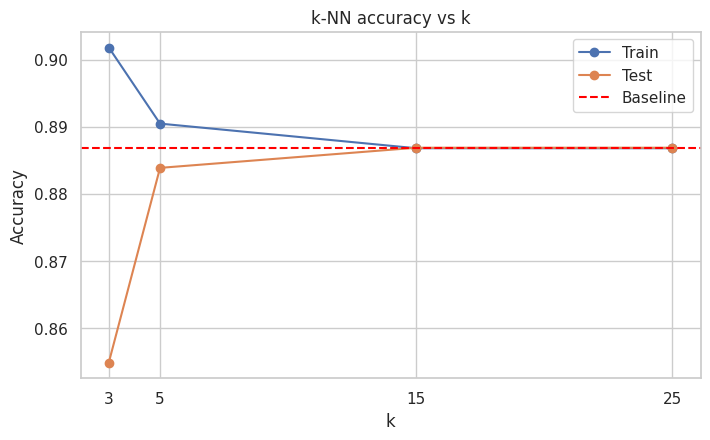

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ks = list(knn_models)
ax.plot(ks, knn_results["train accuracy"], marker="o", label="Train")
ax.plot(ks, knn_results["test accuracy"], marker="o", label="Test")
ax.axhline(test_baseline, color="red", linestyle="--", label="Baseline")
ax.set(xlabel="k", ylabel="Accuracy", title="k-NN accuracy vs k", xticks=ks)
ax.legend();

In [ ]:
# What is k=3 actually doing? Confusion matrix on the test set
cm = confusion_matrix(y_test, knn_models[3].predict(X_test))
pd.DataFrame(cm, index=["actual right", "actual left"], columns=["predicted right", "predicted left"])

,predicted right,predicted left
actual right,850,36
actual left,109,4


**Interpretation**

- **k = 3: overfit.** Training accuracy (≈ 0.90) is noticeably higher than test accuracy (≈ 0.85), and the test score is **below the baseline**. It is the only model that predicts many left-handers, but most of those predictions are wrong (see the confusion matrix). It is fitting noise in the training data.
- **k = 5: slightly overfit.** The train/test gap narrows, but test accuracy (≈ 0.88) is still just **below the baseline**, and it flags only a handful of left-handers.
- **k = 15 and k = 25: underfit / degenerate.** Train and test accuracy both equal the baseline exactly, because these models **predict "right-handed" for everyone**. With only ~11% left-handers, a neighbourhood of 15+ people practically never has a left-handed majority.
- **None of the k-NN models beats the baseline.** Test ROC AUC is around 0.52–0.57 for all four, close to the 0.5 of random guessing. Even ranking people by predicted probability, the models can barely tell left- and right-handers apart.

---

## Step 4 & 5 Modeling: logistic regression

### Create and fit four separate logistic regression models: one with LASSO and $\alpha = 1$, one with LASSO and $\alpha = 10$, one with Ridge and $\alpha = 1$, and one with Ridge and $\alpha = 10$. *(Hint: Be careful with how you specify $\alpha$ in your model!)*

Note: You can use the same train and test data as above.

In [ ]:
def make_logreg(penalty, alpha):
    """Logistic regression with an L1 (LASSO) or L2 (Ridge) penalty of strength alpha.

    scikit-learn uses C = 1 / alpha, so a larger alpha means a SMALLER C.
    scikit-learn 1.8 deprecated `penalty=` in favour of `l1_ratio=`, and older versions
    ignore `l1_ratio` unless penalty='elasticnet', so we pick the right form for the
    installed version. 'liblinear' supports both L1 and L2.
    """
    C = 1 / alpha
    major, minor = (int(v) for v in sklearn.__version__.split(".")[:2])
    if (major, minor) >= (1, 8):
        return LogisticRegression(l1_ratio=1.0 if penalty == "l1" else 0.0, C=C,
                                  solver="liblinear", max_iter=1000)
    return LogisticRegression(penalty=penalty, C=C, solver="liblinear", max_iter=1000)

logreg_models = {}
for penalty, label in [("l1", "LASSO"), ("l2", "Ridge")]:
    for alpha in [1, 10]:
        model = make_logreg(penalty, alpha)
        model.fit(X_train, y_train)
        logreg_models[f"{label} alpha={alpha}"] = model

for name, m in logreg_models.items():
    print(f"{name:<16} C={m.C:<5} non-zero coefficients: {(m.coef_ != 0).sum()} / {len(q_cols)}")

LASSO alpha=1    C=1.0   non-zero coefficients: 42 / 44
LASSO alpha=10   C=0.1   non-zero coefficients: 33 / 44
Ridge alpha=1    C=1.0   non-zero coefficients: 44 / 44
Ridge alpha=10   C=0.1   non-zero coefficients: 44 / 44


### Evaluate your models:

Evaluate each of your four models on the training and testing sets, and interpret the four scores. Are any of your models overfit or underfit? Do any of your models beat the baseline accuracy rate?

In [ ]:
logreg_results = pd.DataFrame([evaluate(m, name) for name, m in logreg_models.items()]).set_index("model")
print(f"Baseline accuracy (test): {test_baseline:.4f}")
logreg_results.round(4)

Baseline accuracy (test): 0.8869


,train accuracy,test accuracy,beats baseline?,lefties predicted (test),recall (left),test ROC AUC
model,,,,,,
LASSO alpha=1,0.8868,0.8869,False,0,0.0,0.5215
LASSO alpha=10,0.8868,0.8869,False,0,0.0,0.5353
Ridge alpha=1,0.8868,0.8869,False,0,0.0,0.5191
Ridge alpha=10,0.8868,0.8869,False,0,0.0,0.5291


In [ ]:
# Even the highest predicted probability of being left-handed stays well below 0.5
for name, m in logreg_models.items():
    p = m.predict_proba(X_test)[:, 1]
    print(f"{name:<16} predicted P(left): min {p.min():.3f}, max {p.max():.3f}")

LASSO alpha=1    predicted P(left): min 0.029, max 0.296
LASSO alpha=10   predicted P(left): min 0.035, max 0.328
Ridge alpha=1    predicted P(left): min 0.028, max 0.295
Ridge alpha=10   predicted P(left): min 0.030, max 0.320


**Interpretation**

- **All four logistic regression models score exactly the baseline** on both training and test sets. They **predict "right-handed" for every respondent**: no individual's predicted probability of being left-handed comes close to the 0.5 threshold, so the model never predicts the rare class.
- **Underfit rather than overfit.** Train and test accuracy are identical, so there is no overfitting. The models simply find no pattern strong enough to override the 89/11 class prior. The cause is the features, not the regularisation: changing α from 1 to 10 or switching L1 ↔ L2 changes nothing about the predictions.
- **The regularisation is still doing its job on the coefficients.** LASSO zeroes out some coefficients, and more of them at α = 10, which is consistent with most items carrying no useful information.
- **None beat the baseline.** Test ROC AUC is about 0.52–0.54, essentially chance.

---

## Step 6: Answer the problem.

Are any of your models worth moving forward with? What are the "best" models?

In [ ]:
all_results = pd.concat([knn_results, logreg_results])
all_results.round(4)

,train accuracy,test accuracy,beats baseline?,lefties predicted (test),recall (left),test ROC AUC
model,,,,,,
kNN k=3,0.9018,0.8549,False,40,0.0354,0.5233
kNN k=5,0.8905,0.8839,False,11,0.0354,0.5374
kNN k=15,0.8868,0.8869,False,0,0.0000,0.5473
kNN k=25,0.8868,0.8869,False,0,0.0000,0.5699
LASSO alpha=1,0.8868,0.8869,False,0,0.0000,0.5215
LASSO alpha=10,0.8868,0.8869,False,0,0.0000,0.5353
Ridge alpha=1,0.8868,0.8869,False,0,0.0000,0.5191
Ridge alpha=10,0.8868,0.8869,False,0,0.0000,0.5291


In [ ]:
# Is this just a threshold problem? Re-weight classes so the model is forced to predict lefties
balanced = LogisticRegression(class_weight="balanced", solver="liblinear", max_iter=1000).fit(X_train, y_train)
pred = balanced.predict(X_test)
print(f"Test accuracy:      {balanced.score(X_test, y_test):.4f}  (baseline {test_baseline:.4f})")
print(f"Recall (left):      {recall_score(y_test, pred):.3f}")
print(f"Precision (left):   {precision_score(y_test, pred):.3f}  (a random guess would get {y_test.mean():.3f})")
print(f"Test ROC AUC:       {roc_auc_score(y_test, balanced.predict_proba(X_test)[:, 1]):.3f}")

Test accuracy:      0.5796  (baseline 0.8869)
Recall (left):      0.389
Precision (left):   0.111  (a random guess would get 0.113)
Test ROC AUC:       0.519


**No, none of these models is worth moving forward with as a predictor of left-handedness.**

- **No model beats the baseline accuracy (≈ 88.7%).** The logistic regressions and the k = 15/25 k-NN models tie with it only because they predict "right-handed" for everyone. The k = 3 and k = 5 k-NN models try to identify left-handers, and that drags their accuracy *below* the baseline.
- **This is not just a threshold problem.** Forcing the model to predict left-handers with `class_weight="balanced"` catches some of them (recall ≈ 0.39), but its precision (≈ 0.11) is no better than the 11.3% base rate. The people it flags are no more likely to be left-handed than a random respondent, and accuracy collapses to about 58%. Across every model, ROC AUC sits around 0.52–0.57, only just above chance.
- **"Best" models:** on accuracy alone, the logistic regression models and k-NN with k = 15/25 are tied for best. They are stable (no train/test gap) but useless, since they are equivalent to the baseline. On ROC AUC, k = 25 ranks marginally best, but the differences between models are tiny and within the noise of a ~1,000-row test set.

**Answering the problem:** this matches the background research. The Q1–Q44 answers contain **almost no information about handedness**: no single item correlates with it by more than about 0.05, and no combination of items predicts it meaningfully better than chance. For the professor, this is evidence of **no meaningful association** between these personality and interest items and left-handedness, rather than evidence for one. A null result can be worth reporting, but it should be framed as such. Any real effects would need a dedicated, validated personality measure (e.g. the Big Five) and probably a much larger sample of left-handers to detect.